In [ ]:
# 1
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# 2
import os

folder_path = "/content/drive/MyDrive/SNN_XAI_PROJECT"

print(os.listdir(folder_path))

['MILK10k_Training_GroundTruth.csv', 'MILK10k_Training_Input.zip', 'MILK10k_Training_Supplement.csv', 'MILK10k_Training_Metadata.csv', 'images', 'paired_dataset.csv', 'test.csv', 'val.csv', 'train.csv', 'MILK10k_Class_Distribution.png']


In [ ]:
# 3
import pandas as pd
import os

folder_path = "/content/drive/MyDrive/SNN_XAI_PROJECT"

metadata = pd.read_csv(os.path.join(folder_path, "MILK10k_Training_Metadata.csv"))
ground_truth = pd.read_csv(os.path.join(folder_path, "MILK10k_Training_GroundTruth.csv"))
supplement = pd.read_csv(os.path.join(folder_path, "MILK10k_Training_Supplement.csv"))

print("METADATA")
print("Shape:", metadata.shape)
print("Columns:", metadata.columns.tolist())
print(metadata.head(3))

print("\nGROUND TRUTH")
print("Shape:", ground_truth.shape)
print("Columns:", ground_truth.columns.tolist())
print(ground_truth.head(3))

print("\nSUPPLEMENT")
print("Shape:", supplement.shape)
print("Columns:", supplement.columns.tolist())
print(supplement.head(3))

METADATA
Shape: (10480, 17)
Columns: ['lesion_id', 'image_type', 'isic_id', 'attribution', 'copyright_license', 'image_manipulation', 'age_approx', 'sex', 'skin_tone_class', 'site', 'MONET_ulceration_crust', 'MONET_hair', 'MONET_vasculature_vessels', 'MONET_erythema', 'MONET_pigmented', 'MONET_gel_water_drop_fluid_dermoscopy_liquid', 'MONET_skin_markings_pen_ink_purple_pen']
    lesion_id          image_type       isic_id      attribution  \
0  IL_0000652  clinical: close-up  ISIC_8149219  MILK study team   
1  IL_0000652         dermoscopic  ISIC_4671410  MILK study team   
2  IL_0003176  clinical: close-up  ISIC_3904045  MILK study team   

  copyright_license image_manipulation  age_approx     sex  skin_tone_class  \
0          CC-BY-NC            altered        70.0    male                1   
1          CC-BY-NC    instrument only        70.0    male                1   
2          CC-BY-NC    instrument only        45.0  female                5   

             site  MONET_ulcerat

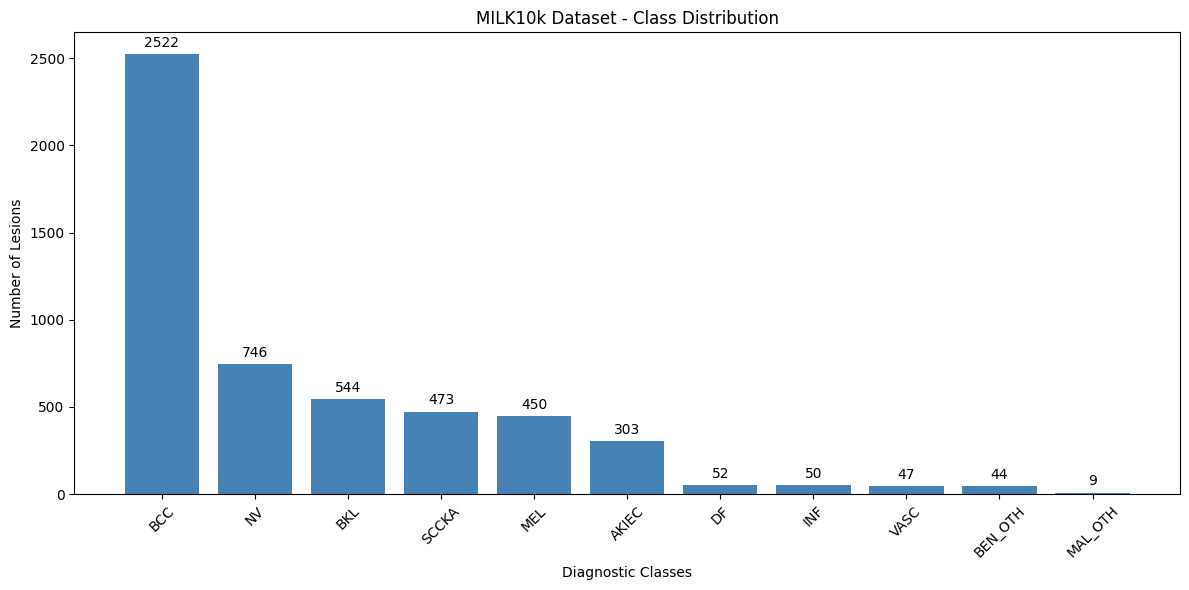

In [ ]:
# 4
import pandas as pd
import matplotlib.pyplot as plt

# Load dataset
folder = "/content/drive/MyDrive/SNN_XAI_PROJECT"
ground_truth = pd.read_csv(f"{folder}/MILK10k_Training_GroundTruth.csv")

# Calculate class distribution
class_counts = ground_truth.drop(columns="lesion_id").sum().sort_values(ascending=False)

# Plot class distribution
plt.figure(figsize=(12, 6))
bars = plt.bar(class_counts.index, class_counts.values, color="steelblue")

plt.bar_label(bars, labels=[str(int(x)) for x in class_counts.values], padding=3)

plt.title("MILK10k Dataset - Class Distribution")
plt.xlabel("Diagnostic Classes")
plt.ylabel("Number of Lesions")
plt.xticks(rotation=45)
plt.tight_layout()

# Save figure
plt.savefig(f"{folder}/MILK10k_Class_Distribution.png", dpi=300)
plt.show()

In [ ]:
# 5
import zipfile
import os

zip_path = "/content/drive/MyDrive/SNN_XAI_PROJECT/MILK10k_Training_Input.zip"

with zipfile.ZipFile(zip_path, "r") as z:
    images = [
        f for f in z.namelist()
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    ]

    zip_ids = {
        os.path.splitext(os.path.basename(f))[0]
        for f in images
    }

print("Total images:", len(images))
print("First 5 images:", images[:5])
print("Missing images:", len(set(metadata["isic_id"]) - zip_ids))

Total images: 10480
First 5 images: ['MILK10k_Training_Input/IL_0000652/ISIC_4671410.jpg', 'MILK10k_Training_Input/IL_0000652/ISIC_8149219.jpg', 'MILK10k_Training_Input/IL_0003176/ISIC_3904045.jpg', 'MILK10k_Training_Input/IL_0003176/ISIC_5371928.jpg', 'MILK10k_Training_Input/IL_0004688/ISIC_0791494.jpg']
Missing images: 0


In [ ]:
# 6
import pandas as pd
import os

folder = "/content/drive/MyDrive/SNN_XAI_PROJECT"

# Pair both image modalities
pairs = metadata.pivot(
    index="lesion_id",
    columns="image_type",
    values="isic_id"
).reset_index()

pairs = pairs.rename(columns={
    "dermoscopic": "dermoscopic_id",
    "clinical: close-up": "closeup_id"
})

# Add diagnosis labels
paired_data = pairs.merge(ground_truth, on="lesion_id")

# Save paired dataset
paired_data.to_csv(f"{folder}/paired_dataset.csv", index=False)

print("Total paired samples:", len(paired_data))
print(paired_data.head())

Total paired samples: 5240
    lesion_id    closeup_id dermoscopic_id  AKIEC  BCC  BEN_OTH  BKL   DF  \
0  IL_0000652  ISIC_8149219   ISIC_4671410    0.0  1.0      0.0  0.0  0.0   
1  IL_0003176  ISIC_3904045   ISIC_5371928    0.0  1.0      0.0  0.0  0.0   
2  IL_0004688  ISIC_0791494   ISIC_3624913    0.0  1.0      0.0  0.0  0.0   
3  IL_0005081  ISIC_5667730   ISIC_5186409    0.0  0.0      0.0  0.0  0.0   
4  IL_0006177  ISIC_8803389   ISIC_1048297    0.0  1.0      0.0  0.0  0.0   

   INF  MAL_OTH  MEL   NV  SCCKA  VASC  
0  0.0      0.0  0.0  0.0    0.0   0.0  
1  0.0      0.0  0.0  0.0    0.0   0.0  
2  0.0      0.0  0.0  0.0    0.0   0.0  
3  0.0      0.0  0.0  0.0    1.0   0.0  
4  0.0      0.0  0.0  0.0    0.0   0.0  


In [ ]:
# 8
import pandas as pd
from sklearn.model_selection import train_test_split

folder = "/content/drive/MyDrive/SNN_XAI_PROJECT"
paired_data = pd.read_csv(f"{folder}/paired_dataset.csv")

classes = [
    "AKIEC", "BCC", "BEN_OTH", "BKL", "DF",
    "INF", "MAL_OTH", "MEL", "NV", "SCCKA", "VASC"
]

paired_data["label"] = paired_data[classes].idxmax(axis=1)

train, temp = train_test_split(
    paired_data,
    test_size=0.30,
    stratify=paired_data["label"],
    random_state=42
)

val, test = train_test_split(
    temp,
    test_size=0.50,
    stratify=temp["label"],
    random_state=42
)

train.to_csv(f"{folder}/train.csv", index=False)
val.to_csv(f"{folder}/val.csv", index=False)
test.to_csv(f"{folder}/test.csv", index=False)

print("Training:", len(train))
print("Validation:", len(val))
print("Testing:", len(test))

print("\nTraining class distribution:")
print(train["label"].value_counts())

Training: 3668
Validation: 786
Testing: 786

Training class distribution:
label
BCC        1765
NV          522
BKL         381
SCCKA       331
MEL         315
AKIEC       212
DF           37
INF          35
VASC         33
BEN_OTH      31
MAL_OTH       6
Name: count, dtype: int64


In [ ]:
# 9
from PIL import Image
import os

folder = "/content/drive/MyDrive/SNN_XAI_PROJECT"
image_folder = f"{folder}/images/MILK10k_Training_Input"

sample = train.iloc[0]
lesion_id = sample["lesion_id"]

for modality in ["dermoscopic_id", "closeup_id"]:
    image_path = os.path.join(
        image_folder,
        lesion_id,
        sample[modality] + ".jpg"
    )

    with Image.open(image_path) as img:
        print(modality, ":", img.size, "| Mode:", img.mode)

dermoscopic_id : (600, 450) | Mode: RGB
closeup_id : (600, 450) | Mode: RGB


In [ ]:
# # 10
# import os
# import pandas as pd
# import torch
# from PIL import Image
# from torch.utils.data import Dataset, DataLoader
# from torchvision import transforms

# folder = "/content/drive/MyDrive/SNN_XAI_PROJECT"
# image_folder = f"{folder}/images/MILK10k_Training_Input"
# classes = ["AKIEC", "BCC", "BEN_OTH", "BKL", "DF", "INF", "MAL_OTH", "MEL", "NV", "SCCKA", "VASC"]

# transform = transforms.Compose([
#     transforms.Resize((96, 128)),
#     transforms.Pad((0, 16, 0, 16)),
#     transforms.ToTensor()
# ])

# class MILK10kDataset(Dataset):
#     def __init__(self, csv_file):
#         self.data = pd.read_csv(csv_file)

#     def __len__(self):
#         return len(self.data)

#     def __getitem__(self, idx):
#         row = self.data.iloc[idx]

#         def load_image(image_id):
#             path = f"{image_folder}/{row['lesion_id']}/{image_id}.jpg"
#             with Image.open(path) as img:
#                 return transform(img.convert("RGB"))

#         derm = load_image(row["dermoscopic_id"])
#         closeup = load_image(row["closeup_id"])
#         label = classes.index(row["label"])
#         return derm, closeup, label

# train_loader = DataLoader(MILK10kDataset(f"{folder}/train.csv"), batch_size=1, shuffle=True)
# val_loader = DataLoader(MILK10kDataset(f"{folder}/val.csv"), batch_size=1, shuffle=False)
# test_loader = DataLoader(MILK10kDataset(f"{folder}/test.csv"), batch_size=1, shuffle=False)

# print("Training pairs:", len(train_loader.dataset))
# print("Validation pairs:", len(val_loader.dataset))
# print("Testing pairs:", len(test_loader.dataset))
# print("Training images:", len(train_loader.dataset) * 2)
# print("Validation images:", len(val_loader.dataset) * 2)
# print("Testing images:", len(test_loader.dataset) * 2)
# print("Total images:", (len(train_loader.dataset) + len(val_loader.dataset) + len(test_loader.dataset)) * 2)

# derm, closeup, labels = next(iter(train_loader))
# print("Dermoscopic:", derm.shape)
# print("Close-up:", closeup.shape)
# print("Labels:", labels.shape)
import pandas as pd,torch
from PIL import Image
from torch.utils.data import Dataset,DataLoader,WeightedRandomSampler
from torchvision import transforms
folder="/content/drive/MyDrive/SNN_XAI_PROJECT"
image_folder=f"{folder}/images/MILK10k_Training_Input"
classes=["AKIEC","BCC","BEN_OTH","BKL","DF","INF","MAL_OTH","MEL","NV","SCCKA","VASC"]
transform=transforms.Compose([transforms.Resize((96,128)),transforms.Pad((0,16,0,16)),transforms.ToTensor()])
class MILK10kDataset(Dataset):
    def __init__(self,csv_file):self.data=pd.read_csv(csv_file)
    def __len__(self):return len(self.data)
    def __getitem__(self,idx):
        row=self.data.iloc[idx]
        def load_image(image_id):
            path=f"{image_folder}/{row['lesion_id']}/{image_id}.jpg"
            with Image.open(path) as img:return transform(img.convert("RGB"))
        return load_image(row["dermoscopic_id"]),load_image(row["closeup_id"]),classes.index(row["label"])
train_df=pd.read_csv(f"{folder}/train.csv")
counts=train_df["label"].value_counts().reindex(classes,fill_value=0)
if (counts==0).any():raise ValueError("Training split contains a class with zero samples")
beta=0.999
n=torch.tensor(counts.values,dtype=torch.float64)
cb_weights=(1-beta)/(1-torch.pow(beta,n))
cb_weights=cb_weights/cb_weights.mean()
sample_weights=train_df["label"].map(dict(zip(classes,cb_weights.sqrt().tolist()))).to_numpy()
sampler=WeightedRandomSampler(torch.tensor(sample_weights,dtype=torch.double),num_samples=len(train_df),replacement=True)
train_loader=DataLoader(MILK10kDataset(f"{folder}/train.csv"),batch_size=1,sampler=sampler,num_workers=0)
val_loader=DataLoader(MILK10kDataset(f"{folder}/val.csv"),batch_size=1,shuffle=False,num_workers=0)
test_loader=DataLoader(MILK10kDataset(f"{folder}/test.csv"),batch_size=1,shuffle=False,num_workers=0)
print("Square-root CB sampling implemented")

Square-root CB sampling implemented


In [ ]:
# 11
%pip install -q snntorch

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 133.6/133.6 kB 12.2 MB/s eta 0:00:00


In [ ]:
12
import torch
import snntorch as snn

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)
print("PyTorch:", torch.__version__)
print("snnTorch:", snn.__version__)

Device: cuda
PyTorch: 2.11.0+cu130
snnTorch: 1.0.0


In [ ]:
# 13
import torch
import torch.nn as nn
import snntorch as snn
from snntorch import surrogate

class SpikingConvBlock(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()

        self.conv1 = nn.Conv2d(in_channels, out_channels, 3, padding=1)
        self.bn1 = nn.BatchNorm2d(out_channels)
        self.if1 = snn.Leaky(beta=1.0, spike_grad=surrogate.fast_sigmoid())
        self.drop1 = nn.Dropout2d(0.2)

        self.conv2 = nn.Conv2d(out_channels, out_channels, 3, padding=1)
        self.bn2 = nn.BatchNorm2d(out_channels)
        self.if2 = snn.Leaky(beta=1.0, spike_grad=surrogate.fast_sigmoid())
        self.drop2 = nn.Dropout2d(0.2)

    def forward(self, x, mem1, mem2):
        spk1, mem1 = self.if1(self.bn1(self.conv1(x)), mem1)
        x = self.drop1(spk1)

        spk2, mem2 = self.if2(self.bn2(self.conv2(x)), mem2)
        x = self.drop2(spk2)

        return x, mem1, mem2


class SpikingVGG13(nn.Module):
    def __init__(self):
        super().__init__()

        channels = [3, 64, 128, 256, 512, 512]

        self.blocks = nn.ModuleList([
            SpikingConvBlock(channels[i], channels[i + 1])
            for i in range(5)
        ])

        self.pool = nn.AvgPool2d(2)

    def forward(self, x, states):
        new_states = []

        for i, block in enumerate(self.blocks):
            x, mem1, mem2 = block(x, *states[i])
            new_states.append((mem1, mem2))

            if i < 4:
                x = self.pool(x)

        return x, new_states


In [ ]:
# 14
class DualBranchSpikingVGG13(nn.Module):
    def __init__(self, num_classes=11, num_steps=10):
        super().__init__()
        self.num_steps = num_steps
        self.derm_branch = SpikingVGG13()
        self.closeup_branch = SpikingVGG13()
        self.fc1 = nn.Linear(2 * 512 * 8 * 8, 1024)
        self.if_fc1 = snn.Leaky(beta=1.0, spike_grad=surrogate.fast_sigmoid())
        self.dropout = nn.Dropout(0.5)
        self.fc2 = nn.Linear(1024, num_classes)
        self.if_fc2 = snn.Leaky(beta=1.0, spike_grad=surrogate.fast_sigmoid())

    def init_states(self, x):
        channels = [64, 128, 256, 512, 512]
        sizes = [128, 64, 32, 16, 8]
        return [(x.new_zeros(x.size(0), ch, size, size), x.new_zeros(x.size(0), ch, size, size)) for ch, size in zip(channels, sizes)]

    def forward(self, derm, closeup):
        derm_states = self.init_states(derm)
        closeup_states = self.init_states(closeup)
        mem_fc1 = derm.new_zeros(derm.size(0), 1024)
        mem_fc2 = derm.new_zeros(derm.size(0), self.fc2.out_features)
        spike_counts = derm.new_zeros(derm.size(0), self.fc2.out_features)

        for t in range(self.num_steps):
            derm_spikes = torch.bernoulli(derm)
            closeup_spikes = torch.bernoulli(closeup)

            derm_features, derm_states = self.derm_branch(derm_spikes, derm_states)
            closeup_features, closeup_states = self.closeup_branch(closeup_spikes, closeup_states)

            derm_flat = torch.flatten(derm_features, 1)
            closeup_flat = torch.flatten(closeup_features, 1)
            fused = torch.cat((derm_flat, closeup_flat), dim=1)

            spk_fc1, mem_fc1 = self.if_fc1(self.fc1(fused), mem_fc1)
            spk_fc1 = self.dropout(spk_fc1)
            spk_fc2, mem_fc2 = self.if_fc2(self.fc2(spk_fc1), mem_fc2)

            spike_counts = spike_counts + spk_fc2

        return spike_counts


dual_model = DualBranchSpikingVGG13().to(device)
print("Dual-Branch Spiking VGG-13 created successfully!")

Dual-Branch Spiking VGG-13 created successfully!


In [ ]:
# Step 15: Loss Function and Optimizer
# criterion = nn.CrossEntropyLoss()
# optimizer = torch.optim.Adam(dual_model.parameters(), lr=0.0001)
import torch.nn as nn
import torch.nn.functional as F
class ClassBalancedFocalLoss(nn.Module):
    def __init__(self,weights,gamma=2.0):
        super().__init__()
        self.register_buffer("weights",weights.float())
        self.gamma=gamma
    def forward(self,outputs,targets):
        ce=F.cross_entropy(outputs,targets,reduction="none")
        pt=torch.exp(-ce)
        loss=self.weights[targets]*(1-pt)**self.gamma*ce
        return loss.mean()
criterion=ClassBalancedFocalLoss(cb_weights.to(device),gamma=2.0)
optimizer=torch.optim.Adam(dual_model.parameters(),lr=0.0001)
print("Class-Balanced Focal Loss implemented")

Class-Balanced Focal Loss implemented


In [ ]:
# Step 16: Training, Validation and Checkpoints
import os,torch
dual_model=DualBranchSpikingVGG13().to(device)
optimizer=torch.optim.Adam(dual_model.parameters(),lr=0.0001)
epochs=2
checkpoint_dir=f"{folder}/checkpoints_class_balanced"
os.makedirs(checkpoint_dir,exist_ok=True)
for epoch in range(epochs):
    dual_model.train()
    train_loss=train_correct=train_total=0
    for batch_idx,(derm,closeup,labels) in enumerate(train_loader):
        derm,closeup,labels=derm.to(device),closeup.to(device),labels.to(device)
        optimizer.zero_grad(set_to_none=True)
        outputs=dual_model(derm,closeup)
        loss=criterion(outputs,labels)
        loss.backward()
        optimizer.step()
        train_loss+=loss.item()
        train_correct+=(outputs.argmax(1)==labels).sum().item()
        train_total+=labels.size(0)
        if (batch_idx+1)%50==0:
            print(f"Epoch {epoch+1} | Batch {batch_idx+1}/{len(train_loader)} | Loss: {loss.item():.4f}",flush=True)
        if (batch_idx+1)%100==0:
            torch.save({"epoch":epoch,"batch":batch_idx+1,"model_state_dict":dual_model.state_dict(),"optimizer_state_dict":optimizer.state_dict(),"num_steps":dual_model.num_steps},f"{checkpoint_dir}/latest_checkpoint.pth")
            print("Checkpoint saved!",flush=True)
    dual_model.eval()
    val_loss=val_correct=val_total=0
    with torch.no_grad():
        for derm,closeup,labels in val_loader:
            derm,closeup,labels=derm.to(device),closeup.to(device),labels.to(device)
            outputs=dual_model(derm,closeup)
            val_loss+=criterion(outputs,labels).item()
            val_correct+=(outputs.argmax(1)==labels).sum().item()
            val_total+=labels.size(0)
    print(f"Epoch {epoch+1}/{epochs}")
    print(f"Training Loss: {train_loss/len(train_loader):.4f}")
    print(f"Training Accuracy: {100*train_correct/train_total:.2f}%")
    print(f"Validation Loss: {val_loss/len(val_loader):.4f}")
    print(f"Validation Accuracy: {100*val_correct/val_total:.2f}%")
    torch.save({"epoch":epoch+1,"batch":len(train_loader),"model_state_dict":dual_model.state_dict(),"optimizer_state_dict":optimizer.state_dict(),"num_steps":dual_model.num_steps},f"{checkpoint_dir}/epoch_{epoch+1}.pth")
    print(f"Epoch {epoch+1} checkpoint saved!",flush=True)

Epoch 1 | Batch 50/3668 | Loss: 0.6378
Epoch 1 | Batch 100/3668 | Loss: 7.6427
Checkpoint saved!
Epoch 1 | Batch 150/3668 | Loss: 0.0318
Epoch 1 | Batch 200/3668 | Loss: 0.6090
Checkpoint saved!
Epoch 1 | Batch 250/3668 | Loss: 0.1803
Epoch 1 | Batch 300/3668 | Loss: 0.1645
Checkpoint saved!
Epoch 1 | Batch 350/3668 | Loss: 0.0599
Epoch 1 | Batch 400/3668 | Loss: 11.2759
Checkpoint saved!


In [ ]:
# checking missing images filw
# from PIL import Image
# import os

# path = "/content/drive/MyDrive/SNN_XAI_PROJECT/images/MILK10k_Training_Input/IL_2955250/ISIC_3540431.jpg"

# print("File exists:", os.path.exists(path))
# print("File size:", os.path.getsize(path) if os.path.exists(path) else "Missing")

# try:
#     with Image.open(path) as img:
#         img.verify()
#     print("Image is valid")
# except Exception as e:
#     print("Image problem:", e)

File exists: True
File size: 0
Image problem: cannot identify image file '/content/drive/MyDrive/SNN_XAI_PROJECT/images/MILK10k_Training_Input/IL_2955250/ISIC_3540431.jpg'


In [ ]:
# restoring images
# import os, zipfile
# from PIL import Image

# folder = "/content/drive/MyDrive/SNN_XAI_PROJECT"
# zip_path = f"{folder}/MILK10k_Training_Input.zip"
# image_id = "ISIC_3540431"
# destination = f"{folder}/images/MILK10k_Training_Input/IL_2955250/{image_id}.jpg"

# with zipfile.ZipFile(zip_path, "r") as z:
#     matches = [name for name in z.namelist() if os.path.basename(name) == f"{image_id}.jpg"]
#     if len(matches) != 1:
#         raise ValueError(f"Expected one image in ZIP, found {len(matches)}")
#     with z.open(matches[0]) as source:
#         image_bytes = source.read()

# temporary = destination + ".tmp"
# try:
#     with open(temporary, "wb") as f:
#         f.write(image_bytes)
#     with Image.open(temporary) as img:
#         img.verify()
#     os.replace(temporary, destination)
# finally:
#     if os.path.exists(temporary):
#         os.remove(temporary)

# print("Image restored successfully!")
# print("File size:", os.path.getsize(destination), "bytes")

Image restored successfully!
File size: 27711 bytes


In [ ]:
# import os,zipfile
# from pathlib import Path
# from PIL import Image
# folder="/content/drive/MyDrive/SNN_XAI_PROJECT"
# root=f"{folder}/images/MILK10k_Training_Input"
# zip_path=f"{folder}/MILK10k_Training_Input.zip"
# mapping=dict(zip(metadata["isic_id"].astype(str),metadata["lesion_id"].astype(str)))
# repaired=0
# with zipfile.ZipFile(zip_path) as z:
#     for i,name in enumerate(z.namelist()):
#         image_id=Path(name).stem
#         if image_id not in mapping or not name.lower().endswith((".jpg",".jpeg",".png")):continue
#         path=f"{root}/{mapping[image_id]}/{Path(name).name}"
#         valid=False
#         if os.path.exists(path) and os.path.getsize(path)>0:
#             try:
#                 with Image.open(path) as img:img.verify()
#                 valid=True
#             except Exception:pass
#         if not valid:
#             os.makedirs(os.path.dirname(path),exist_ok=True)
#             temp=path+".tmp"
#             try:
#                 with z.open(name) as src,open(temp,"wb") as dst:
#                     import shutil
#                     shutil.copyfileobj(src,dst)
#                 with Image.open(temp) as img:img.verify()
#                 os.replace(temp,path)
#                 repaired+=1
#                 print("Restored:",path,flush=True)
#             finally:
#                 if os.path.exists(temp):os.remove(temp)
#         if (i+1)%1000==0:print("Checked:",i+1,"| Repaired:",repaired,flush=True)
# print("Completed. Total repaired:",repaired)

Checked: 1000 | Repaired: 0
Checked: 3000 | Repaired: 0
Checked: 4000 | Repaired: 0
Checked: 6000 | Repaired: 0
Checked: 7000 | Repaired: 0
Checked: 9000 | Repaired: 0
Checked: 10000 | Repaired: 0
Checked: 12000 | Repaired: 0
Checked: 13000 | Repaired: 0
Checked: 15000 | Repaired: 0
Completed. Total repaired: 0


In [ ]:
# dual_model.eval()
# val_loss=val_correct=val_total=0
# with torch.no_grad():
#     for derm,closeup,labels in val_loader:
#         derm,closeup,labels=derm.to(device),closeup.to(device),labels.to(device)
#         outputs=dual_model(derm,closeup)
#         val_loss+=criterion(outputs,labels).item()
#         val_correct+=(outputs.argmax(1)==labels).sum().item()
#         val_total+=labels.size(0)
# print(f"Validation Loss: {val_loss/len(val_loader):.4f}")
# print(f"Validation Accuracy: {100*val_correct/val_total:.2f}%")

Validation Loss: 1.9893
Validation Accuracy: 5.85%


In [ ]:
# from collections import Counter
# dual_model.eval()
# preds,actual=[],[]
# with torch.no_grad():
#     for derm,closeup,labels in val_loader:
#         outputs=dual_model(derm.to(device),closeup.to(device))
#         preds.extend(outputs.argmax(1).cpu().tolist())
#         actual.extend(labels.tolist())
# print("Predicted:",{classes[k]:v for k,v in Counter(preds).items()})
# print("Actual:",{classes[k]:v for k,v in Counter(actual).items()})

Predicted: {'AKIEC': 786}
Actual: {'NV': 112, 'BKL': 82, 'BCC': 379, 'MEL': 67, 'SCCKA': 71, 'AKIEC': 46, 'DF': 7, 'VASC': 7, 'BEN_OTH': 6, 'INF': 7, 'MAL_OTH': 2}
